In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("Customer Churn.csv")
df.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
# Inspect a Data first for perform a EDA

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

**Replacing blanks with 0 as tenure is 0 and no total Charges are recorded and Change a TotalCharges Datatypes String to float**

In [4]:
# Replace a Blank value to 0 Value
df["TotalCharges"]=df["TotalCharges"].replace(" ","0")
#Change a DataType for Object to Float
df["TotalCharges"]=df["TotalCharges"].astype("float")

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

**Check a null value present on your Data**

In [6]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

**Check how many null value present on your data**

In [7]:
df.isnull().sum().sum()

np.int64(0)

In [8]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


**Check a duplicated value present on your Data and Check a customerID through on duplicated value**

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df["customerID"].duplicated().sum()

np.int64(0)

In [11]:
def conv(val):
    if val==1:
        return "yes"
    else:
        return "no"
        
df["SeniorCitizen"]=df["SeniorCitizen"].apply(conv)       

#Converted 0 and 1 values of senior citizen to yes/no to make it easier to undesrtand

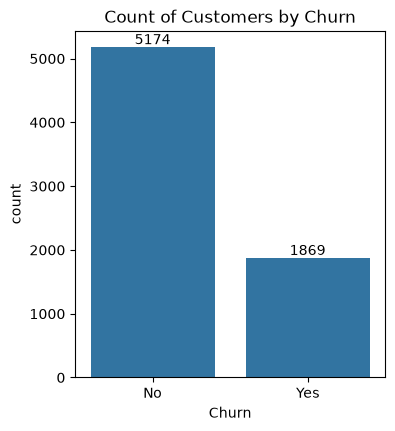

In [12]:
plt.figure(figsize=(4,4.5))
ax=sns.countplot(x="Churn",data=df)

#Check number through how many customers Churn out use a bar_label for count a number
ax.bar_label(ax.containers[0])
plt.title("Count of Customers by Churn")
plt.show()

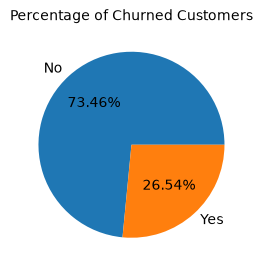

In [64]:
plt.figure(figsize=(3,4))
gb=df.groupby("Churn").agg({'Churn':"count"})
gb
plt.pie(gb["Churn"],labels=gb.index,autopct="%1.2f%%")
plt.title("Percentage of Churned Customers",fontsize=10)
plt.show()

#from the given pie chart we can conclude that 26.54% of our customers have churned out. #not let's explore the reason behind it

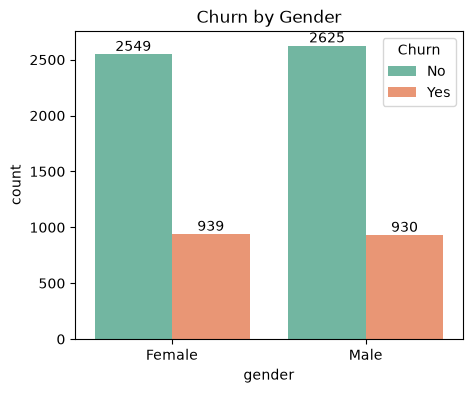

In [62]:
plt.figure(figsize=(5,4))
ax=sns.countplot(x='gender',data=df,hue="Churn",palette='Set2')
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])
plt.title('Churn by Gender')
plt.show()

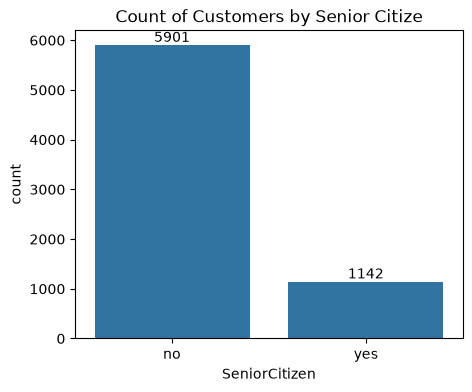

In [61]:
plt.figure(figsize=(5,4))
ax=sns.countplot(x='SeniorCitizen',data=df)
ax.bar_label(ax.containers[0])
plt.title('Count of Customers by Senior Citize')
plt.show()

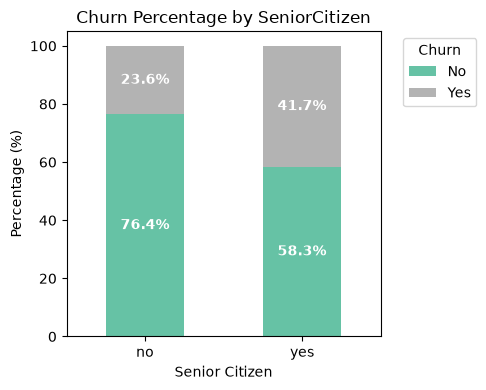

In [33]:

# 1. Calculate proportions (normalize='index' makes rows sum to 100%)
prop_df = pd.crosstab(df['SeniorCitizen'], df['Churn'], normalize='index') * 100

# 2. Plot stacked bar chart
fig, ax = plt.subplots(figsize=(5, 4))
ax = prop_df.plot(kind='bar', stacked=True, ax=ax, colormap='Set2')

# 3. Add percentage labels to the bars
for container in ax.containers:
  # Format labels with '%' sign and skip 0% values if desired
  labels = [f'{v.get_height():.1f}%' if v.get_height() > 0 else '' for v in container]
  ax.bar_label(container, labels=labels, label_type='center', color='white', weight='bold')

plt.title('Churn Percentage by SeniorCitizen')
plt.xlabel('Senior Citizen')
plt.ylabel('Percentage (%)')
plt.legend(title='Churn', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#Compartive a greated percentage of people in senior citizen category have Churned

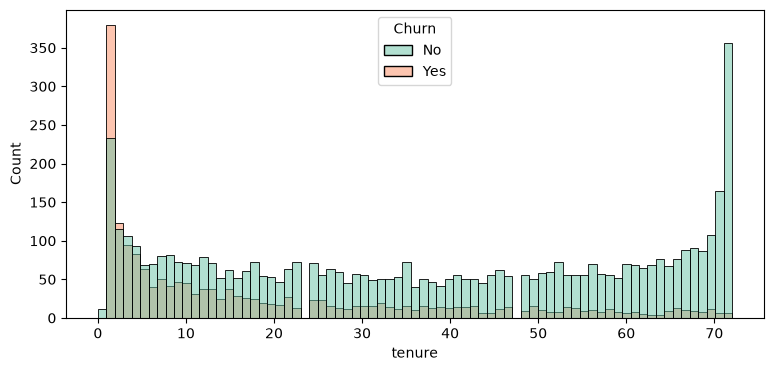

In [59]:
plt.figure(figsize=(9,4))
sns.histplot(x='tenure',data=df,bins=75,hue='Churn',palette='Set2')
plt.show()

#people who have used our services for a long time have stayed and people who have used our services #1 or 2 months have churned

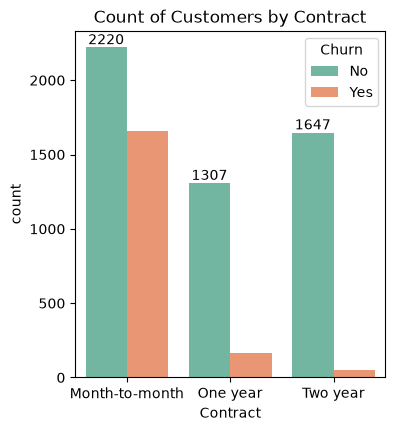

In [58]:
plt.figure(figsize=(4,4.5))
ax=sns.countplot(x="Contract",data=df,hue='Churn',palette='Set2')

#Check number through how many customers Churn out use a bar_label for count a number
ax.bar_label(ax.containers[0])
plt.title("Count of Customers by Contract")
plt.show()

#people who have month to month contarct are likely to churn then from those who have 1 or 2 yeras or contract 

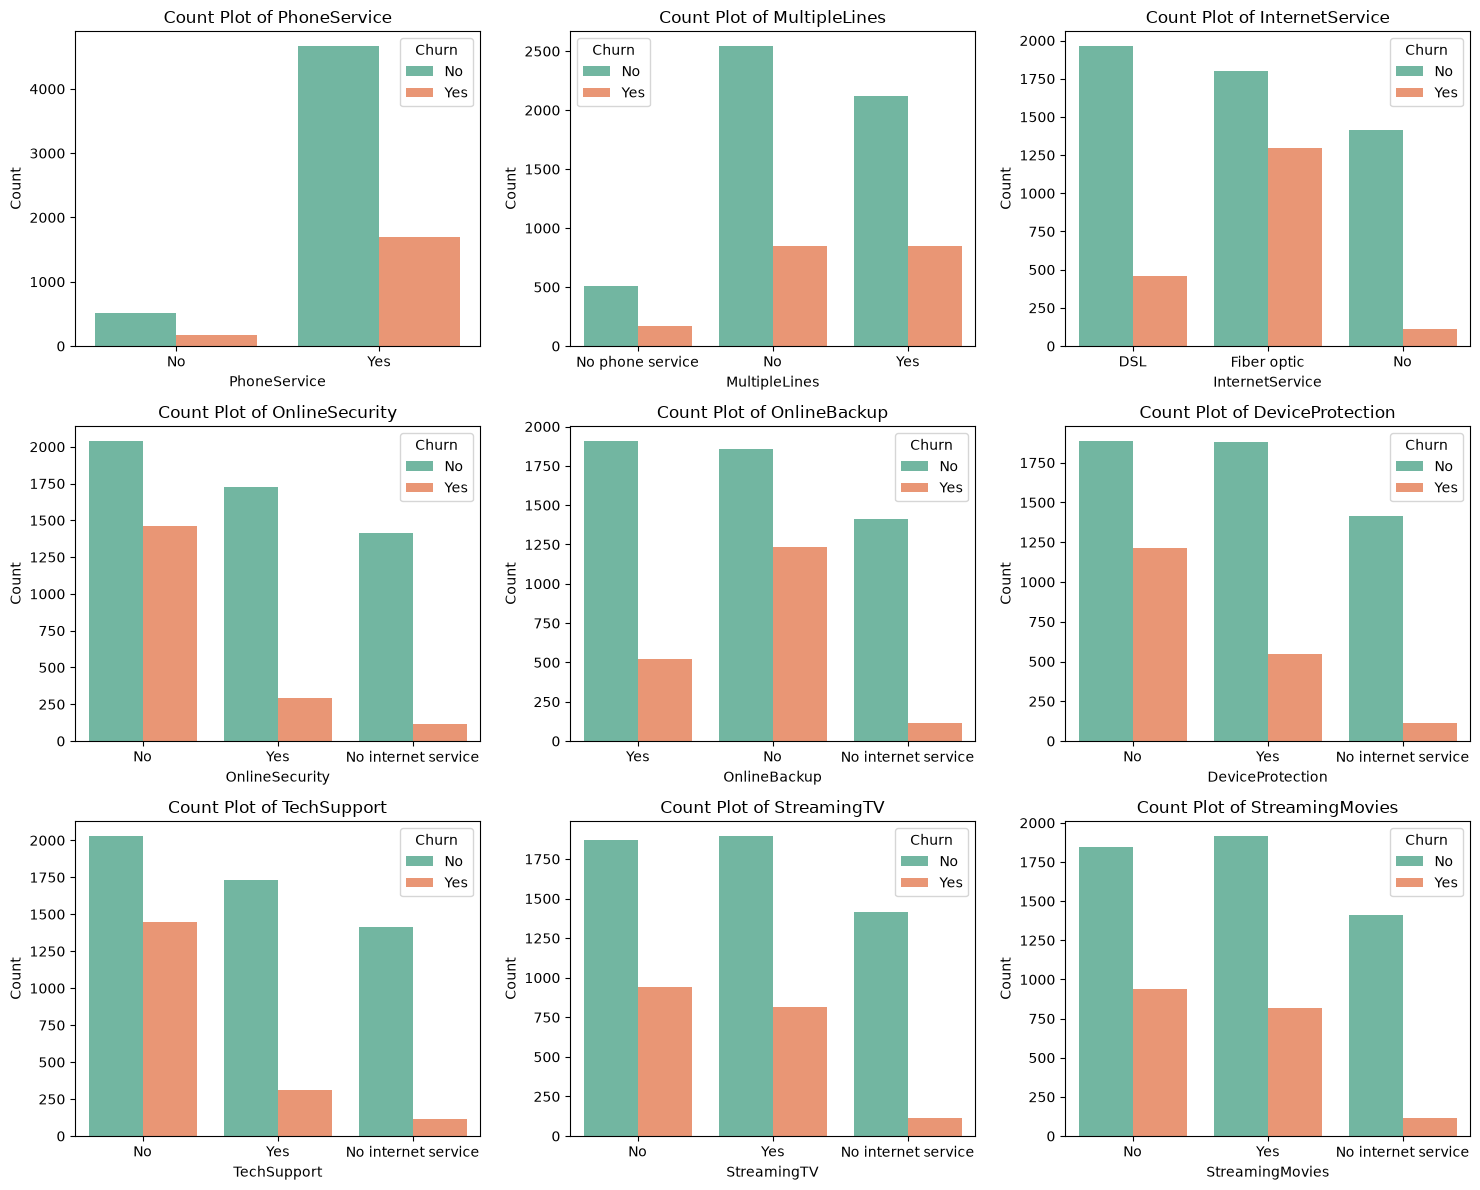

In [52]:
# Define your columns
cols = [
    'PhoneService',
    'MultipleLines',
    'InternetService',
    'OnlineSecurity',
    'OnlineBackup',
    'DeviceProtection',
    'TechSupport',
    'StreamingTV',
    'StreamingMovies',
]

# Create a figure with 3 rows and 3 columns of subplots
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(15, 12))

# Flatten the 2D array of axes for easy iteration
axes = axes.flatten()

# Loop through each column and plot on its respective subplot axis
for i, col in enumerate(cols):
  sns.countplot(x=col, hue='Churn', data=df, ax=axes[i], palette='Set2')
  axes[i].set_title(f'Count Plot of {col}')
  axes[i].set_xlabel(col)
  axes[i].set_ylabel('Count')


# Adjust layout to prevent overlapping labels
plt.tight_layout()
plt.show()

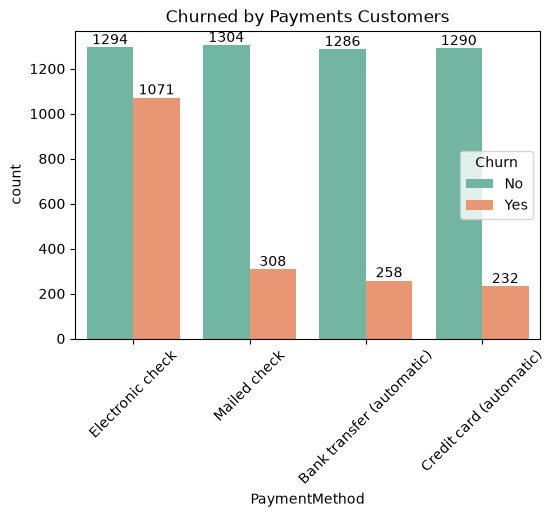

In [57]:
plt.figure(figsize=(6,4))
ax=sns.countplot(x='PaymentMethod',data=df,hue='Churn',palette='Set2')
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])
plt.title('Churned by Payments Customers')
plt.xticks(rotation=45)
plt.show()

#customer is likely to churn when he is using electronic chek as a payment method